# Viscous flow in a rough circular pipe

This notebook runs the AI Buckingham workflow with the case prompt and numerical settings.

Set `OPENAI_API_KEY` and `PARATERA_API_KEY` in the kernel environment. See the repository README for endpoint configuration.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs' / 'cases').is_dir() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))

from ai_buckingham import build_agent_graph
from ai_buckingham.cli import load_case, run_analysis
from ai_buckingham.artifacts import new_run_id, read_json
from IPython.display import display, Markdown
import pandas as pd

D:\zFILES\MiniConda\envs\langchain_\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


In [2]:
CASE_ID = 'rough_pipe'
case = load_case(CASE_ID)
RUN_DIR = ROOT / 'results' / 'cases' / CASE_ID / new_run_id()
display(Markdown(case['prompt']))
frame = pd.read_csv(ROOT / case['dataset'])
print(f'Original observations: {len(frame)}; columns: {list(frame.columns)}')
display(frame.head())
print('Declared manual overrides:')
display(case['manual_hyperparams'])

Perform dimensional analysis for viscous flow in a rough circular pipe to derive the dimensionless relationship governing the pipe friction factor (denoted as f_D).
This analysis uses ONLY the following 5 physical quantities as input parameters:
the fluid density (rho), the dynamic viscosity (mu), the pipe diameter (D), the mean flow velocity (U), and the absolute wall roughness height (epsilon).

Original observations: 1200; columns: ['rho', 'mu', 'D', 'U', 'epsilon', 'f_D']


,rho,mu,D,U,epsilon,f_D
0,0.161916,0.000005,0.562011,12.162270,0.055284,0.100810
1,0.135110,0.000003,0.540736,92.733992,0.023548,0.067180
2,0.155789,0.000005,0.987543,262.405724,0.042243,0.066635
3,0.107534,0.000008,0.724554,106.676034,0.022362,0.057883
4,0.160891,0.000005,0.680638,7.984562,0.053146,0.089136


Declared manual overrides:


{'workflow_template': 'auto_mechanism_adaptive',
 'similarity_type': 'auto',
 'gpr_random_state': 123,
 'mi_method_used': 'binning',
 'mi_param_used': 20,
 'gradient_regime_options': {'surrogate': {'mean_mode': 'affine_sigmoid_transition',
   'max_train_samples': 1100,
   'regime_target_transform': 'log',
   'n_restarts_optimizer': 3,
   'optimizer_maxiter': 2000,
   'log_sigma0_sq_bounds': [-40.0, 40.0],
   'log_sigma1_sq_bounds': [-30.0, 30.0],
   'log_sigma_u_sq_bounds': [-30.0, 5.0]},
  'clustering': {'n_clusters': None,
   'candidate_cluster_counts': [2, 3, 4],
   'min_cluster_fraction': 0.05,
   'eigenvalue_ratio_threshold': 50.0,
   'n_init': 30,
   'max_iter': 200,
   'require_convergence': True}},
 'regime_plot_feature_mode': 'screening_basis',
 'regime_plot_feature_pi_indices': [1, 2],
 'regime_plot_feature_labels': ['$\\log(\\Pi^{(S)}_1)$',
  '$\\log(\\Pi^{(S)}_2)$'],
 'regime_plot_physical_x': {'source': 'power_product',
  'powers': {'U': 1.0, 'rho': 1.0, 'D': 1.0, 'mu': -1

In [3]:
# Build the same nine-node graph used by the CLI and Streamlit.
# This step does not initialize models or make API calls.
agent_graph = build_agent_graph()
print(agent_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	Analyzer(Analyzer)
	Hallu_Checker(Hallu_Checker)
	Basis_Decider(Basis_Decider)
	Basis_Executor(Basis_Executor)
	Workflow_Planner(Workflow_Planner)
	Workflow_Executor(Workflow_Executor)
	Workflow_Replanner(Workflow_Replanner)
	Workflow_Report(Workflow_Report)
	Visualizer(Visualizer)
	__end__([<p>__end__</p>]):::last
	Analyzer --> Hallu_Checker;
	Basis_Decider --> Basis_Executor;
	Basis_Executor -. &nbsp;ready&nbsp; .-> Workflow_Planner;
	Basis_Executor -. &nbsp;failed&nbsp; .-> __end__;
	Hallu_Checker -. &nbsp;retry&nbsp; .-> Analyzer;
	Hallu_Checker -. &nbsp;passed&nbsp; .-> Basis_Decider;
	Hallu_Checker -. &nbsp;blocked&nbsp; .-> __end__;
	Workflow_Executor -. &nbsp;replan&nbsp; .-> Workflow_Replanner;
	Workflow_Executor -. &nbsp;report&nbsp; .-> Workflow_Report;
	Workflow_Planner --> Workflow_Executor;
	Workflow_Replanner --> Workflow_Executor;
	Workflow_Report --> Visualizer;
	__start__ 

## Run the analysis

The following cell runs the graph with the case configuration, saves workflow and optimizer records, and displays the results. Full-budget analyses can take substantial time.

In [4]:
state = run_analysis(CASE_ID, output_dir=RUN_DIR, agent_graph=agent_graph)
manifest = read_json(RUN_DIR / 'manifest.json')
print('Workflow status:', state.get('workflow_status'))
print('Evidence directory:', RUN_DIR.relative_to(ROOT).as_posix())
assert manifest['status'] == 'completed', 'Inspect recorded diagnostics: this run did not complete successfully.'

Q:\Chengao_File\CodeX_\RAG_ablation\prepare_github_\ai-buckingham\src\ai_buckingham\plotting.py:531: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
Q:\Chengao_File\CodeX_\RAG_ablation\prepare_github_\ai-buckingham\src\ai_buckingham\plotting.py:909: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
Q:\Chengao_File\CodeX_\RAG_ablation\prepare_github_\ai-buckingham\src\ai_buckingham\plotting.py:909: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Output constraints,none
Scaling confidence,pending numerical screen
Manual overrides,5
Replanning budget,2


Candidate K,"[2, 3, 4]"
Fixed K,—
Minimum cluster fraction,0.05
Minimum cluster samples,60
Minimum eigenvalue ratio,50
Require convergence,True
Auto K=2 directional support: |cos| <,0.9
Global spectral fraction,Diagnostic only; no decision threshold
Mean mode,affine_sigmoid_transition
Training samples,1100
sigma0²,7.357e+09


Relative MI threshold,≤ 15%
Criteria,MI-only decision: Type I
Screening cosine threshold,0.7
Fixed basis powers during screening,none
Final input constraints,none
Final output constraints,none


Similarity,first kind
Output optimization,False
Output free coefficients,0
Scaling confidence,medium
Fixed input powers,none
Fixed output powers,none
Collinearity penalty,True
Maximum cosine,0.7
Penalize fixed coordinates,True


Restart stability,0.999998


... (4 outputs left out)

Restart stability,1


Restart stability,1


Step,Result,Evidence
Count selection,k=1,k=1 vs k=2; Δscore=6.90836e-05; required ≥ 0.08; beyond uncertainty=False
Sparsification,accepted,"dropped=[""epsilon""]; Δscore=0.000377065; allowed ≤ 0.05"
Rationalization,accepted,relative MI loss=0.00261556; allowed ≤ 0.1
Final model,complete,MI=3.08545; residual=0.0457096; held-out R²=0.973694


Workflow status: success
Evidence directory: results/cases/rough_pipe/20261124T132007Z_432c83c0


In [5]:
# Numeric exports are the common source for reports and the web viewer.
for table in sorted((RUN_DIR / 'tables').glob('*.csv')):
    display(Markdown(f'**{table.name}**'))
    display(pd.read_csv(table).head(30))
print('Final figures:', [p.name for p in sorted((RUN_DIR / 'figures').glob('*'))])
print('Optimizer trace:', (RUN_DIR / 'evidence' / 'optimization_trace.jsonl').relative_to(ROOT).as_posix())

**gradient_field.csv**

,z_1,z_2,gradient_z_1,gradient_z_2,csv_row,regime
0,6.160631,0.575474,-0.252979,0.656029,0,0
1,7.335737,0.403661,-0.220659,0.603461,1,0
2,7.935985,0.617001,-0.212100,0.614359,2,0
3,6.906470,-0.018881,-0.219651,0.561821,3,0
4,6.069263,0.366354,-0.249618,0.632224,4,0
5,7.833441,0.755245,-0.218174,0.634398,5,0
6,8.181560,1.215047,-0.222084,0.682852,6,0
7,5.287056,0.140103,-0.262139,0.624512,7,0
8,5.665063,-0.334375,-0.240673,0.555045,8,0
9,5.731410,-1.216552,-0.215812,0.442694,9,0


**interpretation_knowledge_retrieval_matches.csv**

,entry_id,canonical_name,symbols,aliases,defining_expression,physical_interpretation,domain,source,source_identifier,confidence,retrieval_score,semantic_score,lexical_score,retrieval_mode
0,dg_darcy_friction,Darcy friction factor,f_D,Darcy-Weisbach friction factor; pipe friction ...,f_D = 8 tau_w / (rho U^2) for fully developed ...,Dimensionless wall-friction measure used in pi...,pipe flow,Dimensionless-learning pipe-flow reference,doi:10.1016/j.cma.2023.116728,high,0.691288,0.614110,1.0,semantic_with_lexical_support
1,dg_relative_roughness,relative roughness,epsilon/D; r/D,relative wall roughness,relative_roughness = epsilon / D or r / D,Wall roughness height normalized by pipe diame...,rough-pipe flow,Rough-wall turbulence literature,doi:10.1017/jfm.2020.1085,high,0.660531,0.575664,1.0,semantic_with_lexical_support
2,dg_friction_reynolds,friction Reynolds number,Re_tau; Reτ,wall-friction Reynolds number,Re_tau = u_tau h / nu for channel half-height ...,Compares an outer wall-normal length to the vi...,wall-bounded turbulence,Journal of Fluid Mechanics wall-turbulence ref...,https://www.cambridge.org/core/journals/journa...,curated,0.630522,0.538152,1.0,semantic_with_lexical_support
3,dg_reynolds,Reynolds number,Re,Reynolds number,Re = rho U L / mu = U L / nu,Ratio of inertial to viscous effects based on ...,fluid mechanics,NASA Glenn Boundary Layer,https://www1.grc.nasa.gov/beginners-guide-to-a...,curated,0.614002,0.517503,1.0,semantic_with_lexical_support
4,dg_froude,Froude number,Fr,Froude number,Fr = U / sqrt(g L),Inertia relative to gravity-wave or free-surfa...,free-surface flow; hydraulics,"Wang, A Guide to Fluid Mechanics, Ch. 8 Simila...",doi:10.1017/9781108671149.009,high,0.610794,0.513492,1.0,semantic_with_lexical_support


**metrics.csv**

,path,mutual_information,normalized_information_score,output_optimization,similarity_type,output_label,output_basis_coefficients,output_basis_coordinate_formula,output_basis_expanded_formula,output_physical_exponents,...,primary_seed,restart_count,restart_mutual_information_mean,restart_mutual_information_std,restart_information_score_mean,restart_information_score_std,restart_statistics_scope,subsampling_statistics_scope,stage,output_scaling_reason
0,workflow_result.local_workflows[0].dimension_p...,2.354549,0.094936,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.356587,4.992107e-03,0.094744,4.723669e-04,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
1,workflow_result.local_workflows[0].dimension_p...,2.724714,0.065565,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.724714,6.280370e-16,0.065565,3.254630e-17,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
2,workflow_result.local_workflows[0].locked_solu...,2.354549,0.094936,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.356587,4.992107e-03,0.094744,4.723669e-04,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...
3,workflow_result.local_workflows[0].sparsificat...,2.263406,0.103996,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.263406,0.000000e+00,0.103996,0.000000e+00,current_candidate_cma_restarts,current_candidate_subsampling,NaN,NaN
4,workflow_result.local_workflows[0].rationaliza...,2.198070,0.111017,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.263406,0.000000e+00,0.103996,0.000000e+00,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
5,workflow_result.local_workflows[0].rationaliza...,2.198070,0.111017,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.263406,0.000000e+00,0.103996,0.000000e+00,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
6,workflow_result.local_workflows[0].final_solution,2.198070,0.111017,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,2.263406,0.000000e+00,0.103996,0.000000e+00,inherited_from_pre_rationalization_selected_so...,recomputed_for_rationalized_solution,NaN,NaN
7,workflow_result.local_workflows[0].similarity_...,2.354549,0.094936,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3,2.356587,4.992107e-03,NaN,NaN,NaN,NaN,NaN,NaN
8,workflow_result.local_workflows[0].similarity_...,2.313032,0.098961,NaN,NaN,NaN,NaN,Pi_1**(-0.249) * Pi_2**(-0.35993),[(rho * D * U) / (mu)]**(-0.249) * [(epsilon) ...,NaN,...,NaN,3,2.313032,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN
9,workflow_result.local_workflows[1].dimension_p...,3.101890,0.044964,False,first_kind,f_D,NaN,NaN,NaN,NaN,...,42.0,3,3.101890,0.000000e+00,0.044964,0.000000e+00,current_candidate_cma_restarts,current_candidate_subsampling,count_test,Type I was selected because removing output sc...


... (3 outputs left out)

,csv_row,pi_1,response_original,output_scale,response_transformed
0,0,0.098368,0.100810,1.0,0.100810
1,1,0.043549,0.067180,1.0,0.067180
2,2,0.042776,0.066635,1.0,0.066635
3,3,0.030863,0.057883,1.0,0.057883
4,4,0.078082,0.089136,1.0,0.089136
5,5,0.054062,0.074223,1.0,0.074223
6,6,0.083457,0.092193,1.0,0.092193
7,7,0.085590,0.093880,1.0,0.093880
8,8,0.037822,0.063422,1.0,0.063422
9,9,0.011390,0.040208,1.0,0.040208


**regime_1_collapse.csv**

,csv_row,pi_1,response_original,output_scale,response_transformed
0,12,0.001139,0.072872,1.0,0.072872
1,14,0.001170,0.074894,1.0,0.074894
2,25,0.000436,0.027921,1.0,0.027921
3,28,0.000449,0.028758,1.0,0.028758
4,34,0.000686,0.043919,1.0,0.043919
5,37,0.000544,0.034804,1.0,0.034804
6,43,0.001398,0.089442,1.0,0.089442
7,44,0.000383,0.024525,1.0,0.024525
8,45,0.000331,0.103749,1.0,0.103749
9,49,0.000467,0.029909,1.0,0.029909


Final figures: ['rough_pipe_regime_0_evidence.pdf', 'rough_pipe_regime_0_evidence.png', 'rough_pipe_regime_0_evidence.svg', 'rough_pipe_regime_1_evidence.pdf', 'rough_pipe_regime_1_evidence.png', 'rough_pipe_regime_1_evidence.svg', 'rough_pipe_regime_partition.pdf', 'rough_pipe_regime_partition.png', 'rough_pipe_regime_partition.svg']
Optimizer trace: results/cases/rough_pipe/20261124T132007Z_432c83c0/evidence/optimization_trace.jsonl


## Result files

The run directory contains the state, workflow events, retrieval records, numerical settings, tables and figures. See the [result-file guide](../../docs/evidence.md) for file contents.

[Raw run report](../../results/cases/rough_pipe/20261124T132007Z_432c83c0/report.md)

## Figures

**rough_pipe_regime_0_evidence.png**

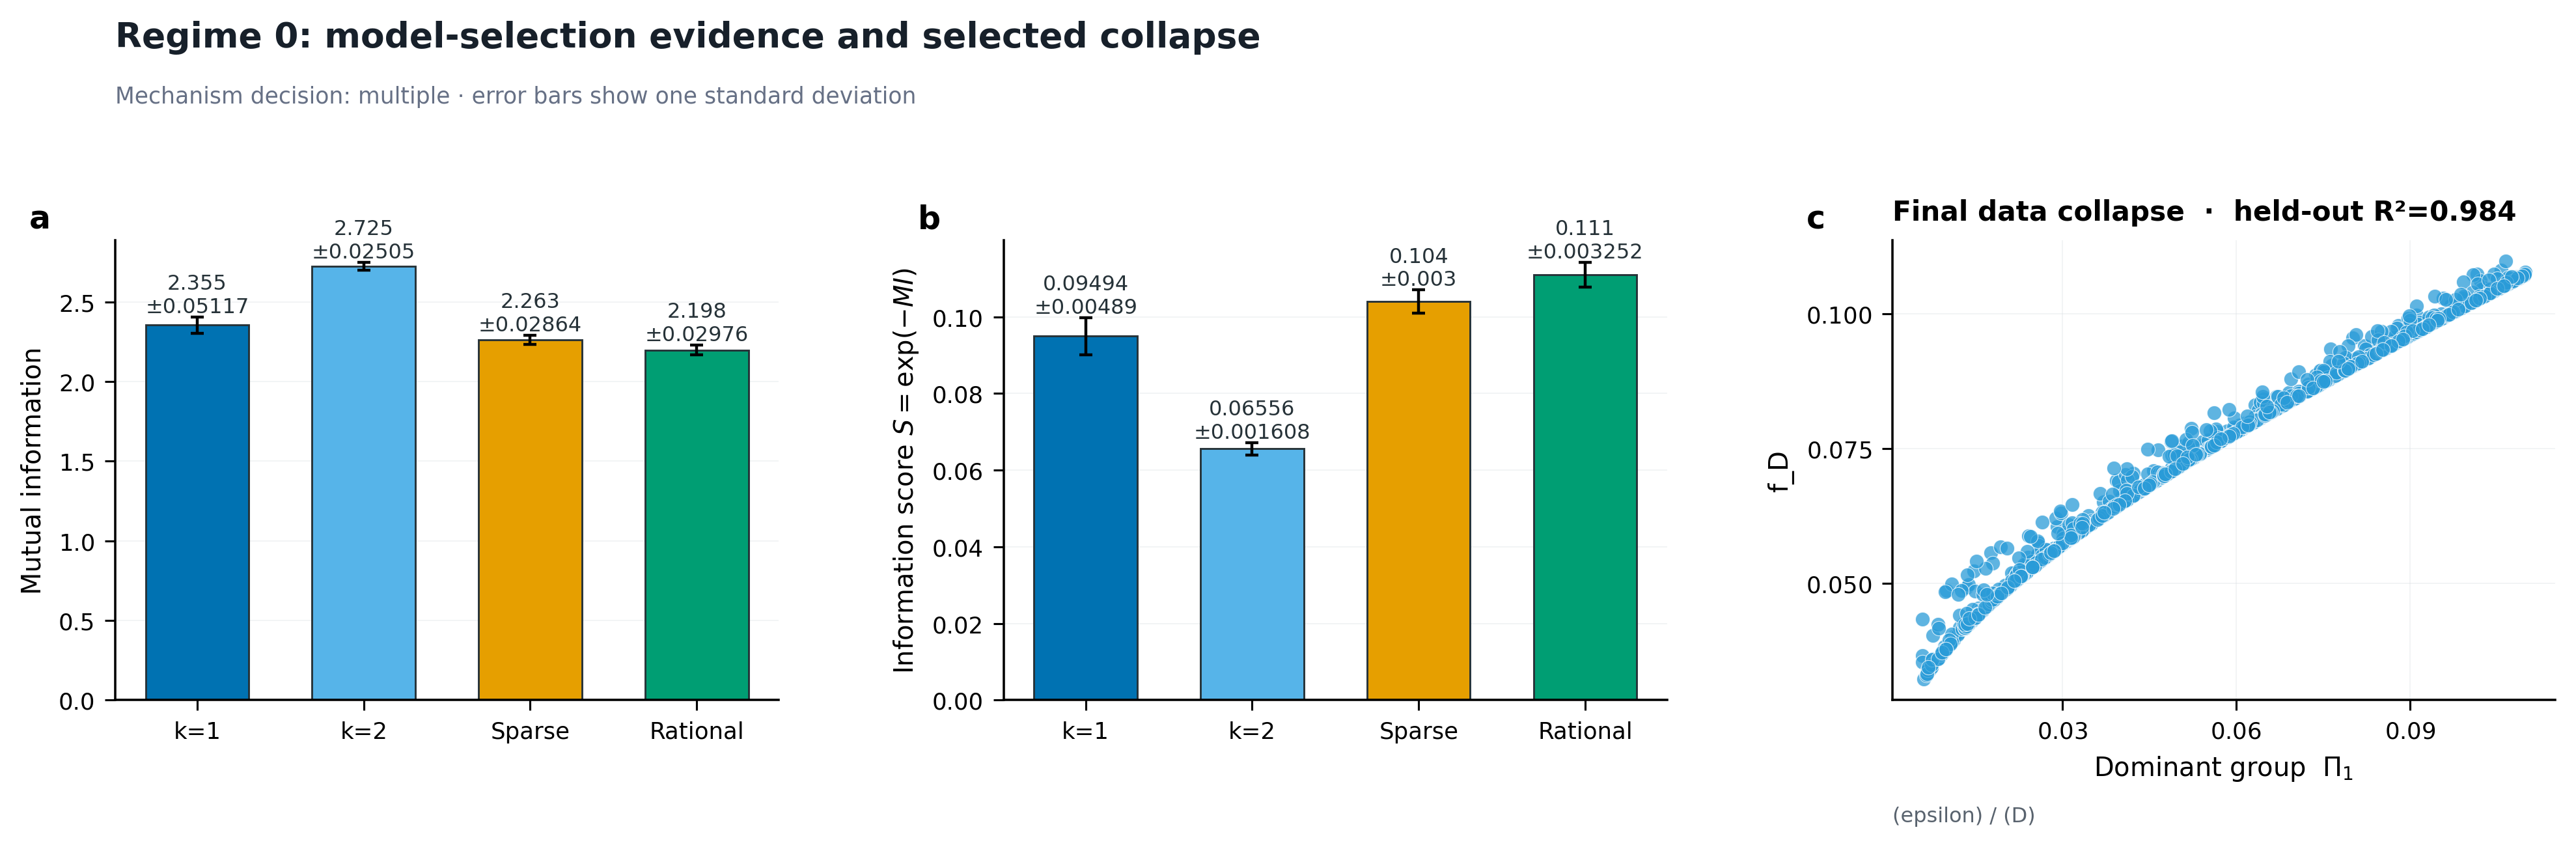

**rough_pipe_regime_1_evidence.png**

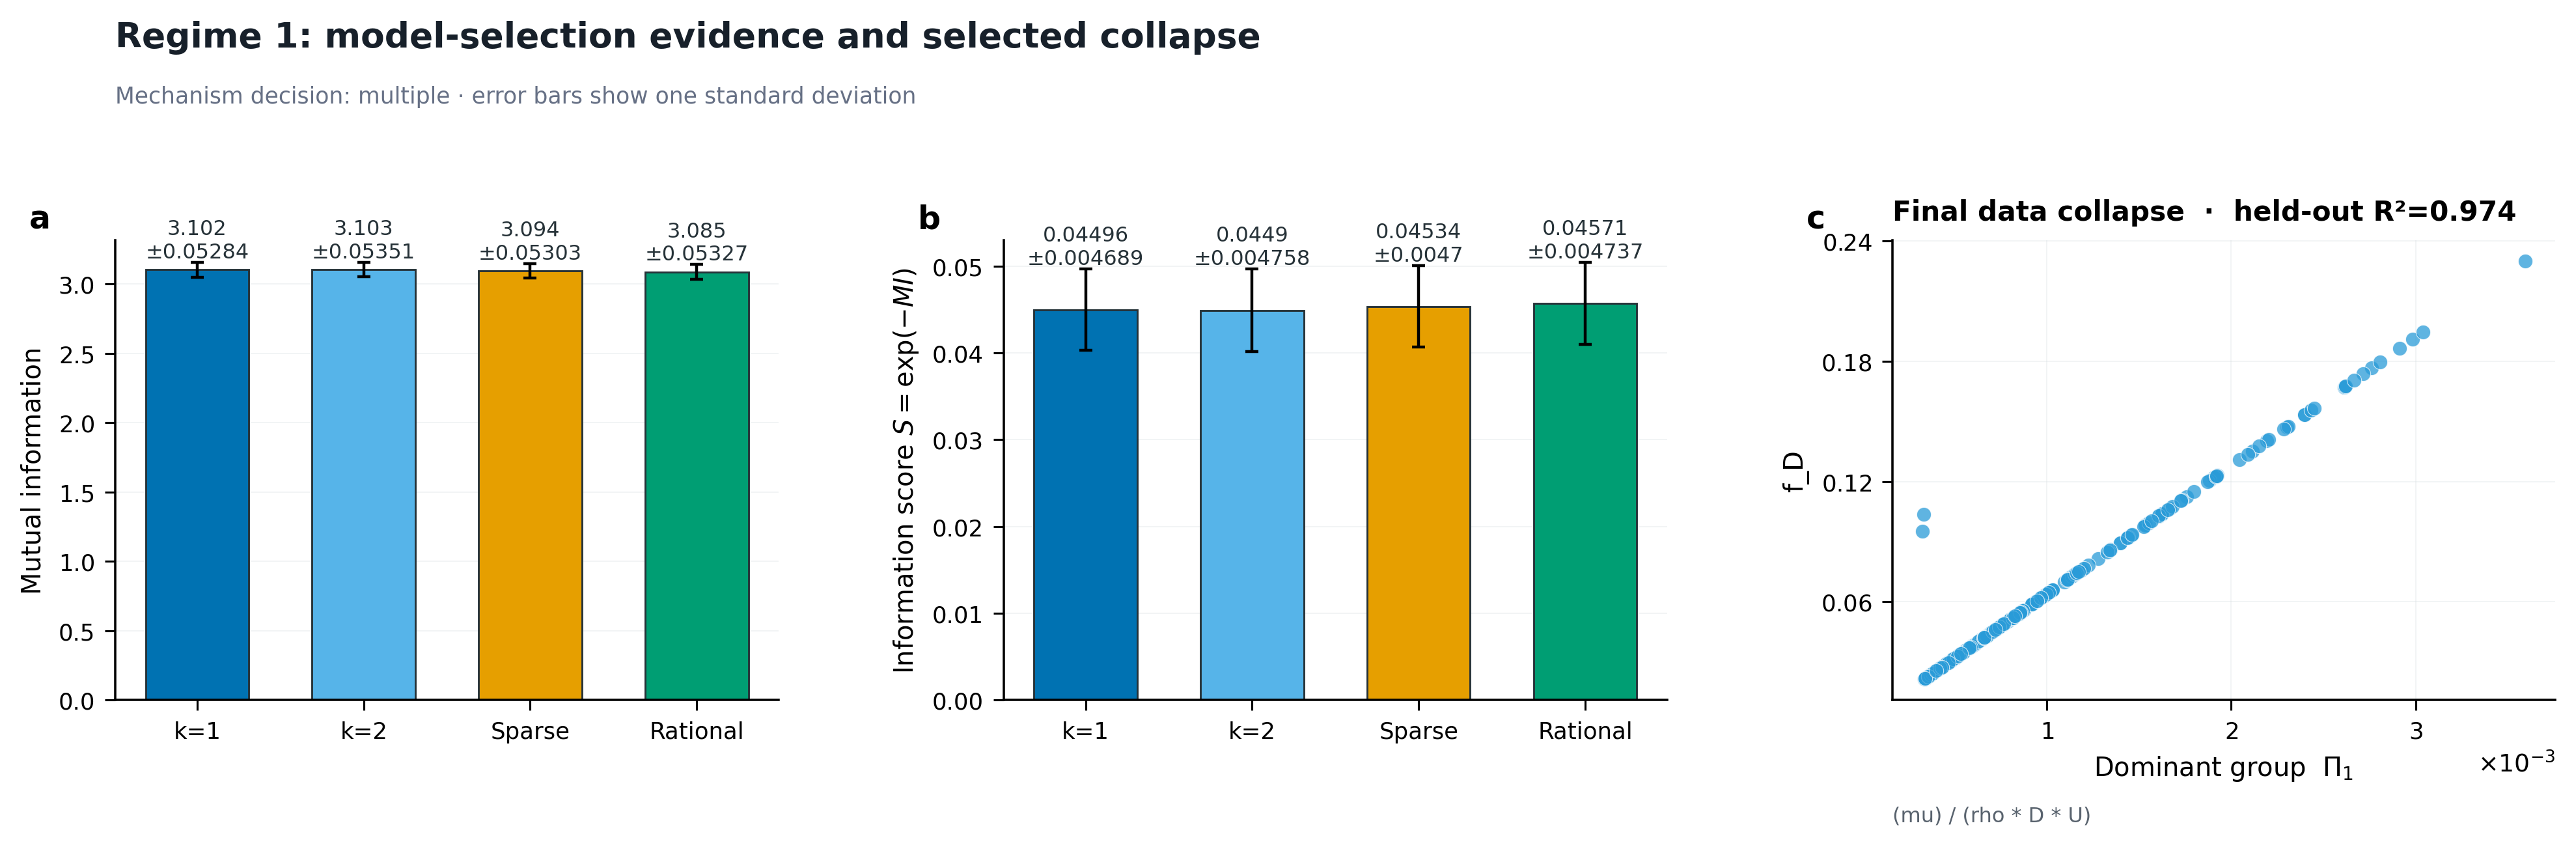

**rough_pipe_regime_partition.png**

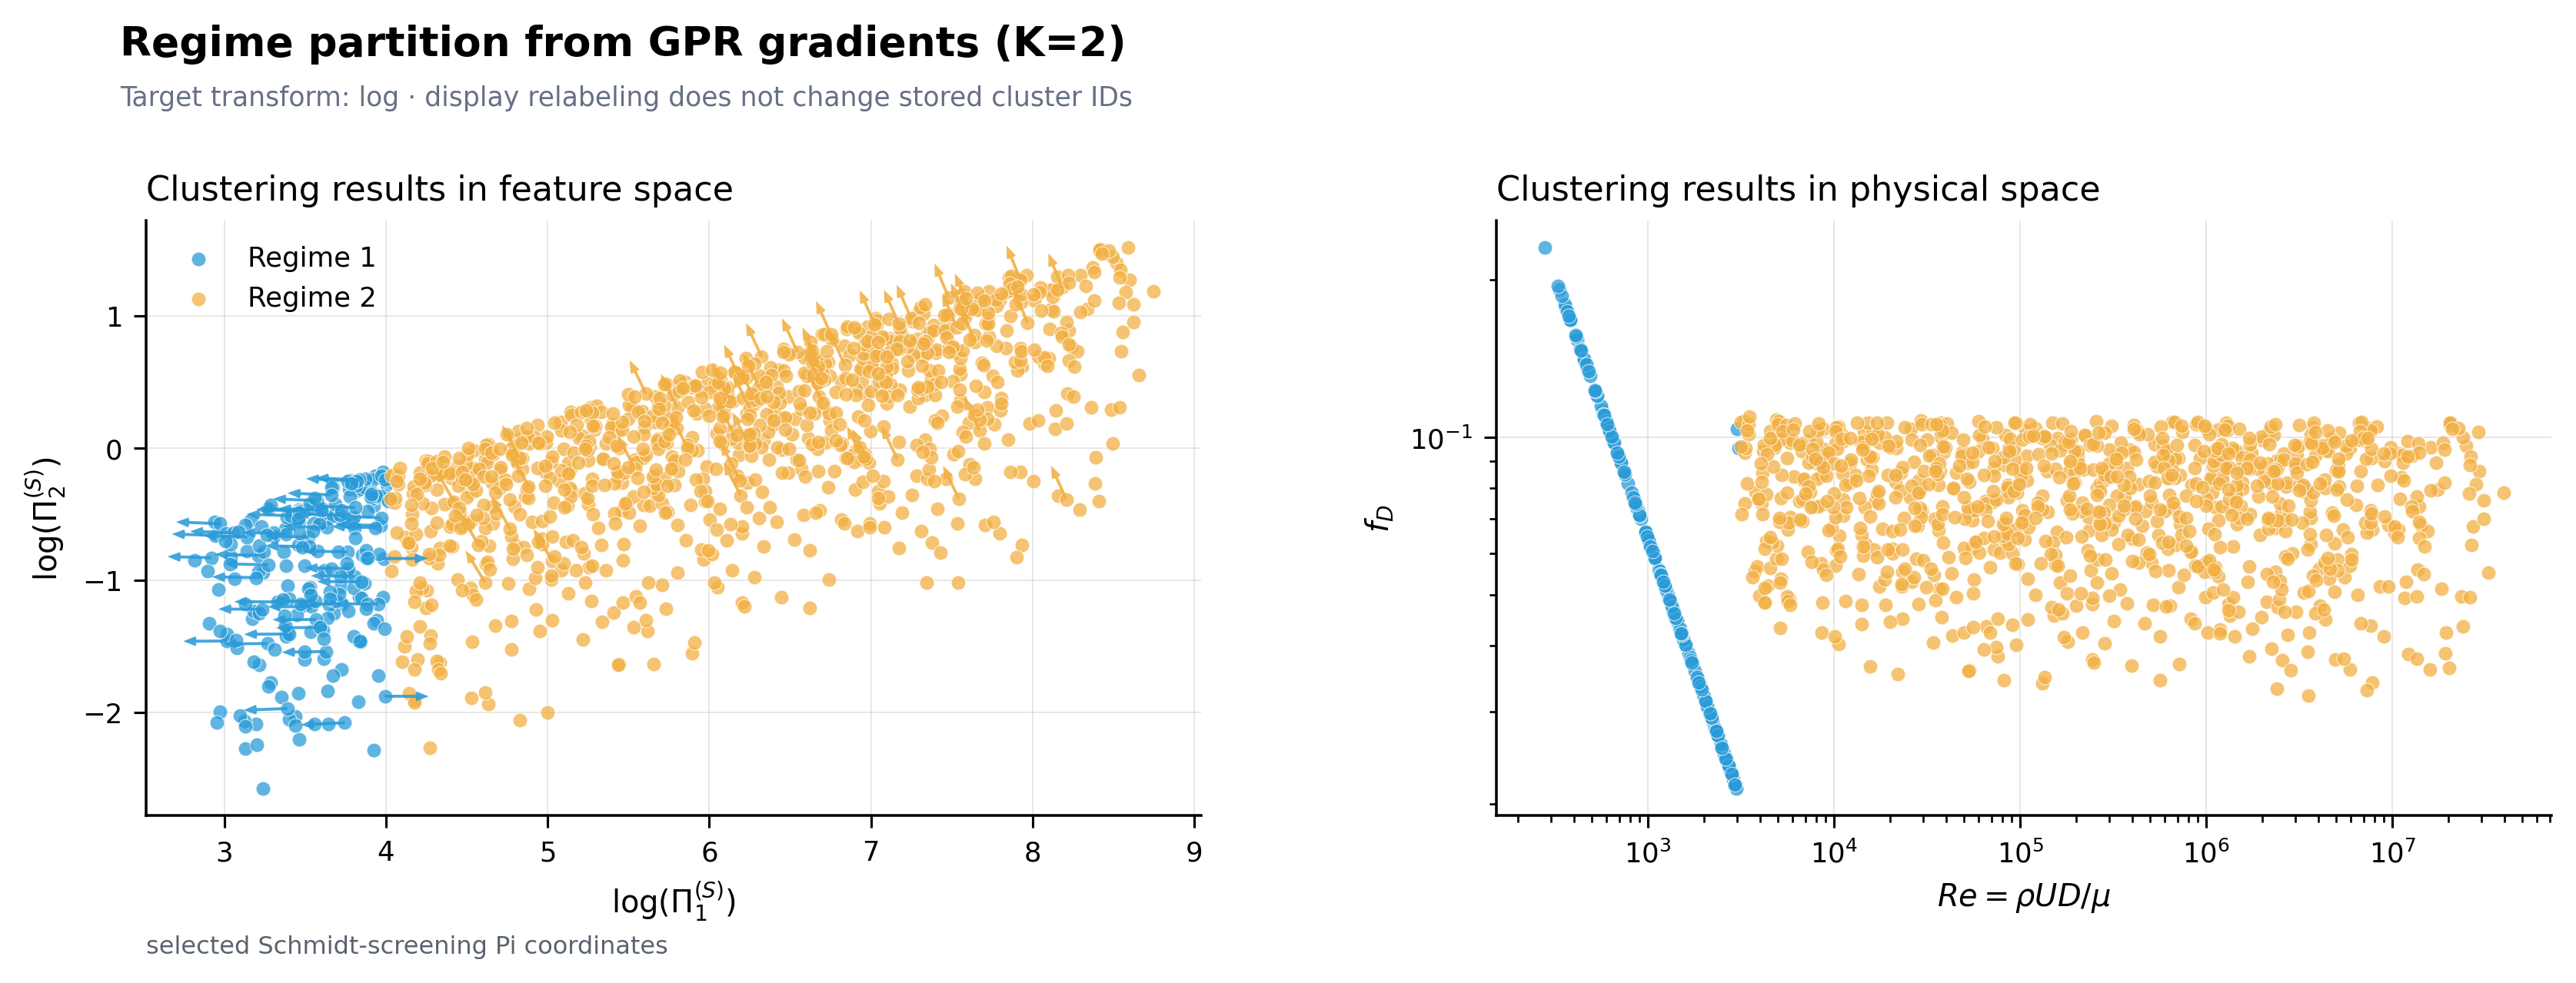